ALGORITMO DE DEUTSCH-JOZSA (Ventaja Cuántica)

🔹 Probando con 3 qubits de entrada:

1. ORÁCULO CONSTANTE:
     ┌───┐      ░  ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░──░─┤ H ├┤M├──────
     ├───┤      ░  ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░──░─┤ H ├─╫─┤M├───
     ├───┤      ░  ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░──░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░  ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░──░───────╫──╫──╫─
     └───┘└───┘ ░  ░       ║  ║  ║ 
c: 3/══════════════════════╩══╩══╩═
                           0  1  2 
Resultados: {'000': 1024}
✅ Si el resultado es '000' (100%), la función es CONSTANTE.

2. ORÁCULO BALANCEADO:
     ┌───┐      ░       ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░───■───░─┤ H ├┤M├──────
     ├───┤      ░   │   ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░───┼───░─┤ H ├─╫─┤M├───
     ├───┤      ░   │   ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░───┼───░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░ ┌─┴─┐ ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░─┤ X ├─░───────╫──╫──╫─
     └───┘└───┘ ░ └───┘ ░       ║  ║  ║ 
c: 3/══════════════

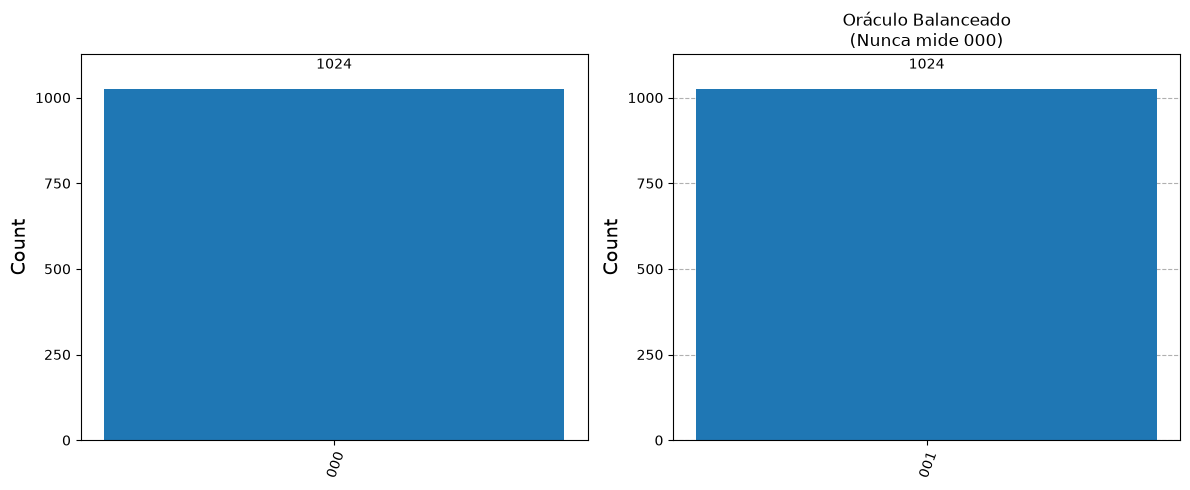


💡 CONCLUSIÓN:
Clásicamente, necesitaríamos hasta 2^(3-1) + 1 = 5 consultas para estar seguros.
Cuánticamente, lo resolvimos con EXACTAMENTE 1 consulta al oráculo.
¡Esta es la primera demostración formal de ventaja cuántica!


In [1]:
# ===================================================
# FASE 4 - TAREA 4.1: Algoritmo de Deutsch-Jozsa
# ===================================================
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("=" * 70)
print("ALGORITMO DE DEUTSCH-JOZSA (Ventaja Cuántica)")
print("=" * 70)

def crear_oraculo_constante(n_qubits):
    """Crea un oráculo que siempre devuelve 0 (o siempre 1, el efecto en la fase es similar)"""
    qc = QuantumCircuit(n_qubits + 1)
    # No hacemos nada (identidad) o aplicamos X al qubit auxiliar. 
    # Para simplificar, dejamos el qubit auxiliar intacto (f(x) = 0)
    return qc

def crear_oraculo_balanceado(n_qubits):
    """Crea un oráculo balanceado (ej. f(x) = x_0, depende solo del primer qubit)"""
    qc = QuantumCircuit(n_qubits + 1)
    # CNOT controlado por el qubit 0, target el qubit auxiliar (n_qubits)
    qc.cx(0, n_qubits)
    return qc

def deutsch_jozsa(n_qubits, tipo_oraculo):
    """Ejecuta el algoritmo de Deutsch-Jozsa"""
    # n_qubits de entrada + 1 qubit auxiliar (ancilla)
    qr = QuantumRegister(n_qubits + 1, 'q')
    cr = ClassicalRegister(n_qubits, 'c') # Solo medimos los qubits de entrada
    qc = QuantumCircuit(qr, cr)
    
    # Paso 1: Preparar el qubit auxiliar en |1> y aplicar H a TODOS los qubits
    qc.x(n_qubits)
    qc.h(range(n_qubits + 1))
    qc.barrier()
    
    # Paso 2: Aplicar el Oráculo
    if tipo_oraculo == "constante":
        oracle = crear_oraculo_constante(n_qubits)
    else:
        oracle = crear_oraculo_balanceado(n_qubits)
    
    qc.compose(oracle, inplace=True)
    qc.barrier()
    
    # Paso 3: Aplicar H a los qubits de entrada (interferencia)
    qc.h(range(n_qubits))
    
    # Paso 4: Medir solo los qubits de entrada
    qc.measure(range(n_qubits), range(n_qubits))
    
    return qc

# --- EJECUCIÓN Y PRUEBA ---
n = 3  # Número de qubits de entrada
simulator = AerSimulator()

print(f"\n🔹 Probando con {n} qubits de entrada:")

# 1. Caso CONSTANTE
qc_const = deutsch_jozsa(n, "constante")
print("\n1. ORÁCULO CONSTANTE:")
print(qc_const.draw("text", fold=120))

job_const = simulator.run(qc_const, shots=1024)
counts_const = job_const.result().get_counts()
print(f"Resultados: {counts_const}")
print("✅ Si el resultado es '000' (100%), la función es CONSTANTE.")

# 2. Caso BALANCEADO
qc_bal = deutsch_jozsa(n, "balanceado")
print("\n2. ORÁCULO BALANCEADO:")
print(qc_bal.draw("text", fold=120))

job_bal = simulator.run(qc_bal, shots=1024)
counts_bal = job_bal.result().get_counts()
print(f"Resultados: {counts_bal}")
print("✅ Si el resultado NO es '000' (probabilidad 0%), la función es BALANCEADA.")

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
plot_histogram(counts_const, ax=ax1, title="Oráculo Constante\n(Siempre mide 000)")
plot_histogram(counts_bal, ax=ax2, title="Oráculo Balanceado\n(Nunca mide 000)")
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("Clásicamente, necesitaríamos hasta 2^(3-1) + 1 = 5 consultas para estar seguros.")
print("Cuánticamente, lo resolvimos con EXACTAMENTE 1 consulta al oráculo.")
print("¡Esta es la primera demostración formal de ventaja cuántica!")

ALGORITMO DE BERNSTEIN-VAZIRANI (Cadena Secreta en 1 Consulta)

🔹 CADENA SECRETA REAL: 101

Circuito:
     ┌───┐      ░            ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░───■────────░─┤ H ├┤M├──────
     ├───┤      ░   │        ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░───┼────────░─┤ H ├─╫─┤M├───
     ├───┤      ░   │        ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░───┼────■───░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░ ┌─┴─┐┌─┴─┐ ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░─┤ X ├┤ X ├─░───────╫──╫──╫─
     └───┘└───┘ ░ └───┘└───┘ ░       ║  ║  ║ 
c: 3/════════════════════════════════╩══╩══╩═
                                     0  1  2 

📊 Resultados: {'101': 1024}

🎯 Cadena descubierta por el algoritmo: 101
✅ ¿Coincide con la cadena secreta? True

🔹 CADENA SECRETA REAL: 110

Circuito:
     ┌───┐      ░            ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░────────────░─┤ H ├┤M├──────
     ├───┤      ░            ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░───■────────░─┤ H ├─╫─┤M├───
     ├───┤      ░   │        ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├

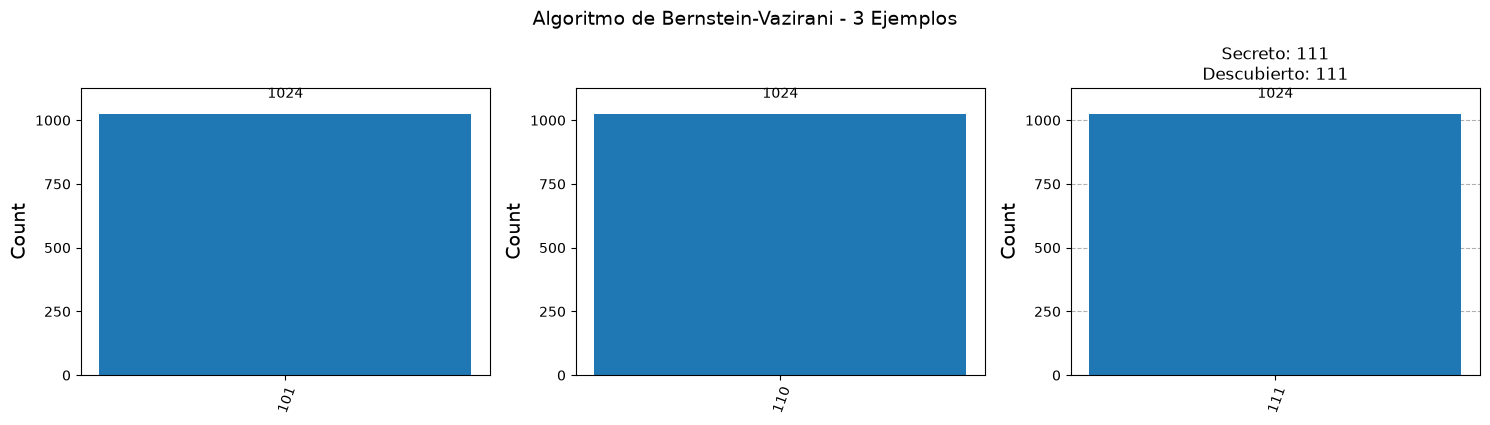


💡 CONCLUSIÓN:
Clásicamente, para encontrar una cadena secreta de 3 bits,
necesitaríamos 3 consultas al oráculo (probar 100, 010, 001).
Cuánticamente, lo encontramos con EXACTAMENTE 1 consulta.

Para n bits:
  - Clásico: n consultas
  - Cuántico: 1 consulta
¡Ventaja cuántica LINEAL confirmada!


In [2]:
# ===================================================
# FASE 4 - TAREA 4.2: Algoritmo de Bernstein-Vazirani
# ===================================================
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("=" * 70)
print("ALGORITMO DE BERNSTEIN-VAZIRANI (Cadena Secreta en 1 Consulta)")
print("=" * 70)

def crear_oraculo_bv(n_qubits, cadena_secreta):
    """
    Crea el oráculo BV para una cadena secreta dada.
    Para cada bit '1' en la cadena secreta, aplica un CNOT controlado 
    por ese qubit al qubit auxiliar.
    """
    qc = QuantumCircuit(n_qubits + 1)
    
    # Recorremos la cadena secreta (de derecha a izquierda por convención de Qiskit)
    for i, bit in enumerate(reversed(cadena_secreta)):
        if bit == '1':
            qc.cx(i, n_qubits)  # CNOT controlado por qubit i, target auxiliar
    
    return qc

def bernstein_vazirani(cadena_secreta):
    """Ejecuta el algoritmo de Bernstein-Vazirani"""
    n = len(cadena_secreta)
    
    qr = QuantumRegister(n + 1, 'q')
    cr = ClassicalRegister(n, 'c')
    qc = QuantumCircuit(qr, cr)
    
    # Paso 1: Preparar el qubit auxiliar en |1> y aplicar H a TODOS los qubits
    qc.x(n)
    qc.h(range(n + 1))
    qc.barrier()
    
    # Paso 2: Aplicar el Oráculo
    oracle = crear_oraculo_bv(n, cadena_secreta)
    qc.compose(oracle, inplace=True)
    qc.barrier()
    
    # Paso 3: Aplicar H a los qubits de entrada (decodificación)
    qc.h(range(n))
    
    # Paso 4: Medir los qubits de entrada
    qc.measure(range(n), range(n))
    
    return qc

# --- EJECUCIÓN Y PRUEBA ---
simulator = AerSimulator()

# Probaremos con 3 cadenas secretas diferentes
cadenas_secretas = ['101', '110', '111']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, secreto in enumerate(cadenas_secretas):
    print(f"\n{'='*70}")
    print(f"🔹 CADENA SECRETA REAL: {secreto}")
    print('='*70)
    
    # Ejecutar el algoritmo
    qc = bernstein_vazirani(secreto)
    print("\nCircuito:")
    print(qc.draw("text", fold=120))
    
    # Simular
    job = simulator.run(qc, shots=1024)
    counts = job.result().get_counts()
    
    # El resultado más frecuente es la cadena secreta descubierta
    resultado_descubierto = max(counts, key=counts.get)
    
    print(f"\n📊 Resultados: {counts}")
    print(f"\n🎯 Cadena descubierta por el algoritmo: {resultado_descubierto}")
    print(f"✅ ¿Coincide con la cadena secreta? {resultado_descubierto == secreto}")
    
    # Visualización
    plot_histogram(counts, ax=axes[idx], title=f"Secreto: {secreto}\nDescubierto: {resultado_descubierto}")

plt.tight_layout()
plt.suptitle("Algoritmo de Bernstein-Vazirani - 3 Ejemplos", fontsize=14, y=1.05)
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("Clásicamente, para encontrar una cadena secreta de 3 bits,")
print("necesitaríamos 3 consultas al oráculo (probar 100, 010, 001).")
print("Cuánticamente, lo encontramos con EXACTAMENTE 1 consulta.")
print("\nPara n bits:")
print("  - Clásico: n consultas")
print("  - Cuántico: 1 consulta")
print("¡Ventaja cuántica LINEAL confirmada!")

In [6]:
# ===================================================
# FASE 4 - TAREA 4.3: Transformada Cuántica de Fourier (QFT) - Versión Manual
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("=" * 70)
print("TRANSFORMADA CUÁNTICA DE FOURIER (QFT) - Construcción Manual")
print("=" * 70)

def build_qft_circuit(n_qubits):
    """Construye el circuito de la QFT manualmente paso a paso."""
    qc = QuantumCircuit(n_qubits, name="QFT")
    
    # 1. Aplicar Hadamard y fases controladas
    for i in range(n_qubits):
        qc.h(i)
        for j in range(i + 1, n_qubits):
            # El ángulo es pi / 2^(j - i)
            theta = np.pi / (2 ** (j - i))
            # cp(theta, control, target)
            qc.cp(theta, j, i)
    
    # 2. Invertir el orden de los qubits con SWAPs
    for i in range(n_qubits // 2):
        qc.swap(i, n_qubits - 1 - i)
        
    return qc

n_qubits = 3
print(f"\n🔹 Aplicando QFT a {n_qubits} qubits")

# Estado inicial: |100> en notación Qiskit (q_0 = 1, q_1 = 0, q_2 = 0)
qc_inicial = QuantumCircuit(n_qubits)
qc_inicial.x(0)  

# Construir y componer la QFT
qft_circuit = build_qft_circuit(n_qubits)
qc_final = qc_inicial.compose(qft_circuit)

print("\nCircuito de la QFT (observa el patrón de H, fases controladas y SWAPs):")
print(qc_final.draw("text", fold=120))

# Analizar el estado resultante
sv_final = Statevector.from_instruction(qc_final)

print("\n" + "=" * 70)
print("RESULTADO DE LA QFT (Resumen de Amplitudes)")
print("=" * 70)
print("Todas las magnitudes son idénticas (1/√8 ≈ 0.354), lo que cambia son las FASES:")

# Imprimimos solo el primero y el último para evitar truncamiento
print(f"  |000> : {sv_final.data[0].real:+.3f} {sv_final.data[0].imag:+.3f}j  (Mag: {abs(sv_final.data[0]):.3f})")
print(f"  |001> : {sv_final.data[1].real:+.3f} {sv_final.data[1].imag:+.3f}j  (Mag: {abs(sv_final.data[1]):.3f})")
print("   ... (patrón de fases continuando) ...")
print(f"  |111> : {sv_final.data[7].real:+.3f} {sv_final.data[7].imag:+.3f}j  (Mag: {abs(sv_final.data[7]):.3f})")

# Verificar probabilidades uniformes
qc_medicion = qc_final.copy()
qc_medicion.measure_all()

simulator = AerSimulator()
job = simulator.run(qc_medicion, shots=1000)
counts = job.result().get_counts()

print("\n📊 Distribución de probabilidades al medir (Uniforme ~12.5% c/u):")
plot_histogram(counts, title=f"QFT de {n_qubits} qubits - Probabilidades Uniformes")
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("✅ La QFT transformó un estado base localizado en una superposición")
print("   donde TODAS las probabilidades son iguales, pero las FASES complejas")
print("   codifican la información original. Esta manipulación de fases es")
print("   el motor que permite a algoritmos como el de Shor encontrar periodos.")

TRANSFORMADA CUÁNTICA DE FOURIER (QFT)

🔹 Aplicando QFT a 3 qubits

Circuito de la QFT:
     ┌───┐                                ┌───┐   
q_0: ┤ X ├───────────────■────────■───────┤ H ├─X─
     └───┘         ┌───┐ │        │P(π/2) └───┘ │ 
q_1: ──────■───────┤ H ├─┼────────■─────────────┼─
     ┌───┐ │P(π/2) └───┘ │P(π/4)                │ 
q_2: ┤ H ├─■─────────────■──────────────────────X─
     └───┘                                        

RESULTADO DE LA QFT (Resumen de Amplitudes)
Todas las magnitudes son idénticas (1/√8 ≈ 0.354), lo que cambia son las FASES:
  |000> : +0.354 +0.000j  (Mag: 0.354)
  |001> : +0.250 +0.250j  (Mag: 0.354)
   ... (patrón de fases continuando) ...
  |111> : +0.250 -0.250j  (Mag: 0.354)

📊 Distribución de probabilidades al medir (Uniforme ~12.5% c/u):

💡 CONCLUSIÓN:
✅ La QFT transformó un estado base localizado en una superposición
   donde TODAS las probabilidades son iguales, pero las FASES complejas
   codifican la información original. Esta manipulac

C:\Users\user\AppData\Local\Temp\ipykernel_12700\3664608930.py:28: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_circuit = QFT(num_qubits=n_qubits, do_swaps=True).decompose()


In [7]:
# ===================================================
# FASE 4 - TAREA 4.4: Algoritmo de Grover (Búsqueda)
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("=" * 70)
print("ALGORITMO DE GROVER: Búsqueda en Base de Datos No Estructurada")
print("=" * 70)

# Vamos a buscar el estado |11> en un espacio de 2 qubits (4 posibilidades: 00, 01, 10, 11)
n_qubits = 2
target_state = '11'
print(f"\n🔹 Buscando el estado objetivo: |{target_state}>")

qc = QuantumCircuit(n_qubits, n_qubits)

# PASO 1: Inicialización (Superposición uniforme)
# Ponemos todos los qubits en superposición para que todas las posibilidades sean igualmente probables
qc.h(range(n_qubits))
qc.barrier()
print("\n1. Inicialización: Superposición uniforme creada.")

# PASO 2: El Oráculo (Marca el estado |11>)
# Para marcar |11>, aplicamos una compuerta CZ (Controlled-Z).
# Esto invierte la fase del estado |11> (lo vuelve negativo), dejando los demás intactos.
qc.cz(0, 1)
qc.barrier()
print("2. Oráculo: Se aplicó una fase negativa al estado |11>.")

# PASO 3: El Operador de Difusión (Amplificación de amplitud)
# Secuencia estándar de difusión: H -> X -> CZ (controlado por todos) -> X -> H
qc.h(range(n_qubits))
qc.x(range(n_qubits))
qc.cz(0, 1)  # Esta es la reflexión sobre el promedio
qc.x(range(n_qubits))
qc.h(range(n_qubits))
qc.barrier()
print("3. Difusión: Se amplificó la amplitud del estado marcado y se cancelaron los demás.")

# PASO 4: Medición
qc.measure(range(n_qubits), range(n_qubits))

print("\n" + "=" * 70)
print("CIRCUITO COMPLETO DE GROVER (2 Qubits, Objetivo: |11>)")
print("=" * 70)
print(qc.draw("text", fold=120))

# SIMULACIÓN Y VERIFICACIÓN
simulator = AerSimulator()
job = simulator.run(qc, shots=1024)
counts = job.result().get_counts()

print("\n📊 Resultados de 1024 mediciones:")
print(counts)

# Visualización
plot_histogram(counts, title="Algoritmo de Grover: Amplificación del estado |11>")
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("¡El algoritmo funcionó! En lugar de tener un 25% de probabilidad")
print("para cada uno de los 4 estados, la interferencia cuántica amplificó")
print("la probabilidad del estado |11> a casi el 100% en una sola iteración.")
print("\nPara N elementos:")
print("  - Clásico: ~N/2 consultas en promedio.")
print("  - Cuántico: ~π/4 * √N consultas.")
print("¡Esta es la aceleración cuadrática de Grover!")

ALGORITMO DE GROVER: Búsqueda en Base de Datos No Estructurada

🔹 Buscando el estado objetivo: |11>

1. Inicialización: Superposición uniforme creada.
2. Oráculo: Se aplicó una fase negativa al estado |11>.
3. Difusión: Se amplificó la amplitud del estado marcado y se cancelaron los demás.

CIRCUITO COMPLETO DE GROVER (2 Qubits, Objetivo: |11>)
     ┌───┐ ░     ░ ┌───┐┌───┐   ┌───┐┌───┐ ░ ┌─┐   
q_0: ┤ H ├─░──■──░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░─┤M├───
     ├───┤ ░  │  ░ ├───┤├───┤ │ ├───┤├───┤ ░ └╥┘┌─┐
q_1: ┤ H ├─░──■──░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──╫─┤M├
     └───┘ ░     ░ └───┘└───┘   └───┘└───┘ ░  ║ └╥┘
c: 2/═════════════════════════════════════════╩══╩═
                                              0  1 

📊 Resultados de 1024 mediciones:
{'11': 1024}

💡 CONCLUSIÓN:
¡El algoritmo funcionó! En lugar de tener un 25% de probabilidad
para cada uno de los 4 estados, la interferencia cuántica amplificó
la probabilidad del estado |11> a casi el 100% en una sola iteración.

Para N elementos:
  - C

In [10]:
# ===================================================
# FASE 4 - TAREA 4.5: Algoritmo de Shor (Conceptual) - Versión Limpia
# ===================================================
import numpy as np
import math
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("=" * 70)
print("ALGORITMO DE SHOR: Factorización de N = 15 (Conceptual)")
print("=" * 70)

# --- REUTILIZAMOS LA FUNCIÓN DE QFT MANUAL DE LA TAREA 4.3 ---
def build_qft_circuit(n_qubits):
    """Construye el circuito de la QFT manualmente (sin deprecations)."""
    qc = QuantumCircuit(n_qubits, name="QFT")
    for i in range(n_qubits):
        qc.h(i)
        for j in range(i + 1, n_qubits):
            theta = np.pi / (2 ** (j - i))
            qc.cp(theta, j, i)
    for i in range(n_qubits // 2):
        qc.swap(i, n_qubits - 1 - i)
    return qc

# --- PASOS CLÁSICOS DEL ALGORITMO ---
N = 15
a = 7
print(f"\n🔹 Objetivo: Factorizar N = {N}")
print(f"🔹 Base elegida (coprima con N): a = {a}")

# PASO 1 y 2: Encontrar el periodo 'r' de f(x) = a^x mod N
print("\n1. Buscando el periodo 'r' de f(x) = 7^x mod 15:")
r = None
for x in range(1, 10):
    resultado = (a**x) % N
    print(f"   f({x}) = {a}^{x} mod {N} = {resultado}")
    if resultado == 1:
        r = x
        print(f"   ✅ ¡Patrón encontrado! El periodo es r = {r}")
        break

# PASO 3: La parte cuántica (QFT Inversa para estimar el periodo)
print("\n2. FASE CUÁNTICA: Estimación del periodo usando QFT Inversa")
print("   (En un circuito real, aquí iría el oráculo de exponenciación modular)")

n_qubits_qft = 3
qc_shor = QuantumCircuit(n_qubits_qft, n_qubits_qft)

# Superposición inicial simulada del registro de fase
qc_shor.h(range(n_qubits_qft))
qc_shor.barrier()

# QFT INVERSA MANUAL (sin usar la clase deprecada)
# La QFT inversa es la QFT normal con ángulos negativos y orden inverso de SWAPs
qft_inv = build_qft_circuit(n_qubits_qft).inverse()
qc_shor.compose(qft_inv, inplace=True)
qc_shor.barrier()
qc_shor.measure(range(n_qubits_qft), range(n_qubits_qft))

print("\nCircuito conceptual de la fase de estimación (QFT Inversa Manual):")
print(qc_shor.draw("text", fold=100))

simulator = AerSimulator()
job = simulator.run(qc_shor, shots=1024)
counts = job.result().get_counts()

print("\n📊 Resultados de la medición del registro de fase:")
plot_histogram(counts, title="Salida de la QFT Inversa (Picos en múltiplos del periodo)")
plt.show()

# PASO 4: Factorización clásica usando el periodo 'r'
print("\n" + "=" * 70)
print("3. FASE CLÁSICA FINAL: Calcular los factores usando r =", r)
print("=" * 70)

if r % 2 == 0:
    factor1 = math.gcd(a**(r//2) - 1, N)
    factor2 = math.gcd(a**(r//2) + 1, N)
    print(f"   r es par. Calculamos MCD(a^(r/2) ± 1, N)")
    print(f"   MCD({a}^({r}//2) - 1, {N}) = MCD({a**(r//2) - 1}, {N}) = {factor1}")
    print(f"   MCD({a}^({r}//2) + 1, {N}) = MCD({a**(r//2) + 1}, {N}) = {factor2}")
    
    if factor1 > 1 and factor2 > 1 and factor1 * factor2 == N:
        print(f"\n🎉 ¡ÉXITO! Los factores de {N} son {factor1} y {factor2}.")
    else:
        print("\n⚠️ El algoritmo devolvió factores triviales. Se debe reintentar con otro 'a'.")
else:
    print("   r es impar. El algoritmo falla para esta 'a'. Se debe elegir otro 'a'.")

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("El poder de Shor no está en la división, sino en usar la QFT para")
print("encontrar el PERIODO de una función en tiempo polinomial.")
print("Si N tuviera 2048 bits, una computadora clásica tardaría miles de años,")
print("mientras que una computadora cuántica con suficientes qubits lo haría en horas.")
print("Por esto, la criptografía RSA está preparando la 'migración post-cuántica'.")

ALGORITMO DE SHOR: Factorización de N = 15 (Conceptual)

🔹 Objetivo: Factorizar N = 15
🔹 Base elegida (coprima con N): a = 7

1. Buscando el periodo 'r' de f(x) = 7^x mod 15:
   f(1) = 7^1 mod 15 = 7
   f(2) = 7^2 mod 15 = 4
   f(3) = 7^3 mod 15 = 13
   f(4) = 7^4 mod 15 = 1
   ✅ ¡Patrón encontrado! El periodo es r = 4

2. FASE CUÁNTICA: Estimación del periodo usando QFT Inversa
   (En un circuito real, aquí iría el oráculo de exponenciación modular)

Circuito conceptual de la fase de estimación (QFT Inversa Manual):
     ┌───┐ ░                                            ┌───┐ ░ ┌─┐      
q_0: ┤ H ├─░──X──────────────────────■─────────■────────┤ H ├─░─┤M├──────
     ├───┤ ░  │                ┌───┐ │         │P(-π/2) └───┘ ░ └╥┘┌─┐   
q_1: ┤ H ├─░──┼───────■────────┤ H ├─┼─────────■──────────────░──╫─┤M├───
     ├───┤ ░  │ ┌───┐ │P(-π/2) └───┘ │P(-π/4)                 ░  ║ └╥┘┌─┐
q_2: ┤ H ├─░──X─┤ H ├─■──────────────■────────────────────────░──╫──╫─┤M├
     └───┘ ░    └───┘            